In [1]:
import os
import pickle
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.transactions import (
    build_author_transactions,
    build_author_year_transactions,
    save_transactions,
    load_transactions,
)

USE_SAMPLE = False

if USE_SAMPLE:
    DATA_PATH = "../data/sample/dblp_sample_2024.parquet"
    OUT_DIR = "../data/sample"
    SUFFIX = "_sample"
else:
    DATA_PATH = "../data/processed/dblp_clean_2015_2025.parquet"
    OUT_DIR = "../data/processed"
    SUFFIX = ""

FIGURES_DIR = "../figures"
STATS_OUT_DIR = "../data/results"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)

df = pd.read_parquet(DATA_PATH)
print(f"Data: {DATA_PATH}")
print(f"Jumlah paper: {len(df):,} | tahun: {df['year'].min()}-{df['year'].max()}")

Data: ../data/processed/dblp_clean_2015_2025.parquet
Jumlah paper: 1,997,159 | tahun: 2015-2025


In [ ]:
# item = venue_code, transaksi = himpunan venue yang pernah didatangi author
# author-based: 1 transaksi per author, author-year-based: 1 transaksi per (author, tahun)
author_tx = build_author_transactions(df, return_keys=True)
ay_tx = build_author_year_transactions(df, return_keys=True)

# simpan dalam format kontrak list[set[str]] 
save_transactions(author_tx.tolist(), f"{OUT_DIR}/tx_author_based{SUFFIX}.pkl")
save_transactions(ay_tx.tolist(), f"{OUT_DIR}/tx_author_year_based{SUFFIX}.pkl")

# Simpan tahun per transaksi dengan urutan yang sama; diperlukan untuk membagi E ke periode.
year_keys_path = f"{OUT_DIR}/tx_author_year_years{SUFFIX}.pkl"
year_keys = ay_tx.index.get_level_values("year").to_numpy(dtype="uint16")
with open(year_keys_path, "wb") as keys_file:
    pickle.dump(year_keys, keys_file, protocol=pickle.HIGHEST_PROTOCOL)

loaded = load_transactions(f"{OUT_DIR}/tx_author_based{SUFFIX}.pkl")
assert isinstance(loaded, list) and isinstance(loaded[0], set)
assert len(loaded) == len(author_tx)
loaded_ay = load_transactions(f"{OUT_DIR}/tx_author_year_based{SUFFIX}.pkl")
assert len(loaded_ay) == len(ay_tx) == len(year_keys)
assert loaded_ay[:3] == ay_tx.iloc[:3].tolist()
print(f"Transactional DB tersimpan ke: {OUT_DIR}")
print(f"Tahun transaksi Author-Year tersimpan ke: {year_keys_path}")

In [3]:
# contoh transaksi dari tiap kelompok panjang: 1 item, 2-4 item, >=5 item
def sample_examples(tx: pd.Series, n_per_bucket: int = 4, seed: int = 42) -> pd.DataFrame:
    lens = tx.map(len)
    buckets = {"1 item": lens == 1, "2-4 item": lens.between(2, 4), ">=5 item": lens >= 5}
    parts = []
    for label, mask in buckets.items():
        sub = tx[mask]
        if len(sub) == 0:
            continue
        pick = sub.sample(min(n_per_bucket, len(sub)), random_state=seed)
        parts.append(pd.DataFrame({
            "kelompok": label,
            "jumlah_item": pick.map(len),
            "items": pick.map(lambda s: ", ".join(sorted(s))),
        }))
    return pd.concat(parts)

pd.set_option("display.max_colwidth", 120)
print("Contoh transaksi Author-Based:")
display(sample_examples(author_tx))

Contoh transaksi Author-Based:


,kelompok,jumlah_item,items
author,,,
Maarten S. van Leeuwen,1 item,1,miip
Xuanping Qiu,1 item,1,case
Abriele Qudsi,1 item,1,icse
Muhammad Sarim Zafar,1 item,1,sose
Anna T. Winslow,2-4 item,2,"embc, smc"
Chao Zhang 0019,2-4 item,2,"isscc, vlsic"
Lukas Wind,2-4 item,3,"date, drc, iscas"
Junyi Le,2-4 item,2,"icpads, trustcom"
Bahjat Kawar,>=5 item,7,"cvpr, iccv, iccvw, iclr, icml, nips, wacv"


In [4]:
print("Contoh transaksi Author-Year-Based:")
display(sample_examples(ay_tx))

Contoh transaksi Author-Year-Based:


,,kelompok,jumlah_item,items
author,year,,,
Clyde Dunn,2020,1 item,1,irps
Heba Elfardy,2019,1 item,1,naacl
Zhenguo Sun,2019,1 item,1,icira
Yinggan Tang,2023,1 item,1,smc
Ming Sun,2019,2-4 item,3,"icdm, iconip, mlicom"
Basit Khurram,2020,2-4 item,2,"eurosp, icde"
Zhiwen Ren,2025,2-4 item,2,"iccai, nips"
Han Lu 0004,2023,2-4 item,2,"cvpr, iclr"
Will Dabney,2021,>=5 item,5,"aaai, aistats, iclr, icml, nips"


In [5]:
# jumlah transaksi
print(f"Jumlah transaksi Author-Based      : {len(author_tx):,}")
print(f"Jumlah transaksi Author-Year-Based : {len(ay_tx):,}")

Jumlah transaksi Author-Based      : 1,821,649
Jumlah transaksi Author-Year-Based : 4,085,395


In [6]:
# jumlah item unik dan statistik panjang transaksi
def summarize(tx: pd.Series, name: str) -> dict:
    lens = tx.map(len)
    return {
        "representasi": name,
        "jumlah_transaksi": len(tx),
        "jumlah_item_unik": len(set().union(*tx)),
        "rata2_panjang": round(lens.mean(), 3),
        "median_panjang": lens.median(),
        "maks_panjang": lens.max(),
        "transaksi_1_item": int((lens == 1).sum()),
        "persen_1_item": round((lens == 1).mean() * 100, 2),
    }

summary = pd.DataFrame([
    summarize(author_tx, "Author-Based"),
    summarize(ay_tx, "Author-Year-Based"),
])
summary.to_csv(f"{STATS_OUT_DIR}/task3_summary{SUFFIX}.csv", index=False)
summary

,representasi,jumlah_transaksi,jumlah_item_unik,rata2_panjang,median_panjang,maks_panjang,transaksi_1_item,persen_1_item
0,Author-Based,1821649,4372,2.664,1.0,332,1063846,58.40
1,Author-Year-Based,4085395,4372,1.590,1.0,85,2902340,71.04


In [7]:
# distribusi panjang transaksi (jumlah transaksi per banyaknya item)
len_dist = pd.DataFrame({
    "Author-Based": author_tx.map(len).value_counts().sort_index(),
    "Author-Year-Based": ay_tx.map(len).value_counts().sort_index(),
}).fillna(0).astype(int)
len_dist.index.name = "panjang_transaksi"
len_dist.to_csv(f"{STATS_OUT_DIR}/task3_length_distribution{SUFFIX}.csv")
len_dist.head(15)

,Author-Based,Author-Year-Based
panjang_transaksi,,
1,1063846,2902340
2,291739,661137
3,140845,253301
4,83978,116776
5,55323,60756
6,38475,33757
7,28316,19892
8,21232,12382
9,16261,7601


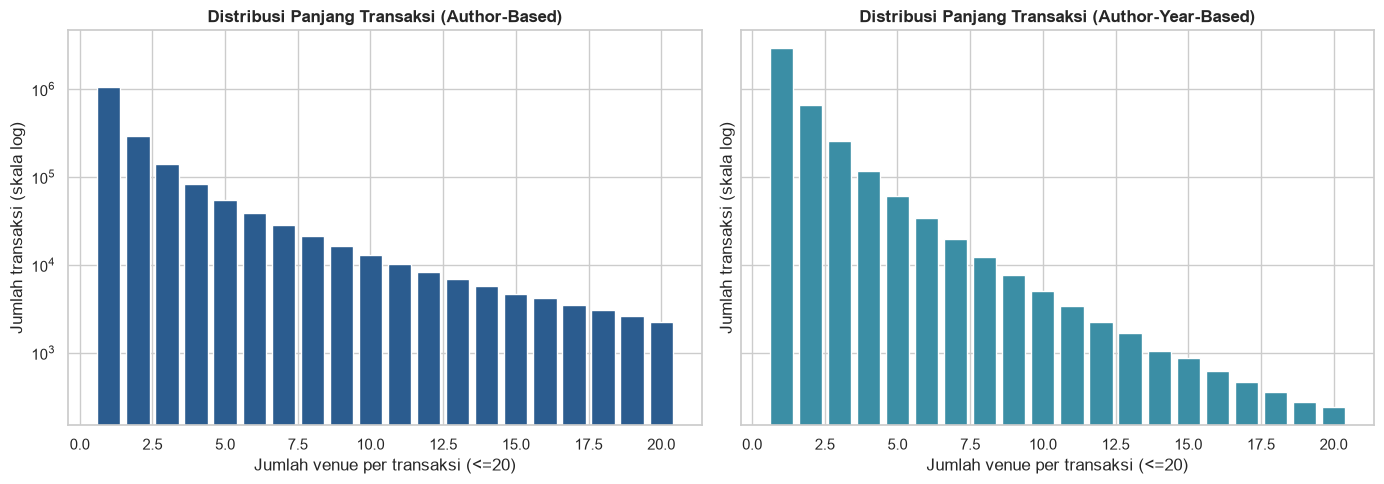

In [8]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, col, color in zip(axes, len_dist.columns, ["#2b5c8f", "#3b8ea5"]):
    data = len_dist[col]
    data = data[data.index <= 20]
    ax.bar(data.index, data.values, color=color)
    ax.set_yscale("log")
    ax.set_title(f"Distribusi Panjang Transaksi ({col})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Jumlah venue per transaksi (<=20)")
    ax.set_ylabel("Jumlah transaksi (skala log)")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task3_transaction_length{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()